# Urban heat at LA28 Olympic venues (scratch solution)

**Proposed final project Task 2. Scratch notebook for the instructor, not student-facing.**

Every place students need something we haven't covered in class is marked with 🆕 **Not covered in class:**

Summary of what's new for students:

1. Filtering a STAC search by cloud cover (`query=` parameter).
2. Choosing one item out of several that intersect the area (pick the one whose footprint contains the whole city).
3. Reading the scale and offset from the STAC metadata and converting the raster to degrees Celsius. The values stored in the file are integers, and the file's own attributes say `scale_factor: 1.0`, which is wrong for this product.
4. Buffering points (`.buffer()`) to turn venue locations into areas.
5. Calculating a statistic per polygon (a simple loop over venues with `rio.clip()`).

Everything else (STAC access with `pystac_client`, `open_rasterio` from an asset href, `squeeze`, `clip_box` + `clip`, no-data values, `points_from_xy`, `to_crs`, `contextily`) was covered in lessons 11 to 17 or discussion section 8.

## About

**Event.** NASA JPL's ECOSTRESS team is working with the LA28 Olympics committee on heat mitigation for venues, transportation corridors and pedestrian areas ahead of the 2028 Games. They released a map of afternoon street temperatures in Los Angeles. In this task you will make a similar (simpler) analysis with Landsat data: how hot does the ground get around LA28 venues compared to the city as a whole?

**Question.** On a clear late-summer day, which LA28 venues sit in areas hotter than the city average, and how much of the area around each venue is hotter than average?

**Why Landsat and not ECOSTRESS?** ECOSTRESS is not on the Microsoft Planetary Computer and needs a NASA Earthdata account. Landsat Collection 2 Level-2 includes a surface temperature band and needs no account.

## About the data

1. **Landsat Collection 2 Level-2 surface temperature** (`landsat-c2-l2` collection, `lwir11` asset), from the Microsoft Planetary Computer STAC catalog. Pixels are 30 m, resampled from the thermal sensor's native 100 m.
2. **Los Angeles city boundary**: US Census Bureau TIGER/Line 2025 Places shapefile for California (`tl_2025_06_place.zip`, downloaded from https://www2.census.gov/geo/tiger/TIGER2025/PLACE/).
3. **LA28 venue locations**: coordinates typed in by hand from the LA28 venue list.

> **Instructor note:** I typed the venue coordinates from memory of well-known stadium locations. Check them against the official LA28 venue list before giving this to students, and check which events each venue will host.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import rioxarray as rioxr
import contextily as ctx

from shapely.geometry import shape  # To turn GeoJSON dictionaries into geometries
from pystac_client import Client
import planetary_computer

## Polygons: Los Angeles city boundary

The Census Places shapefile has every city in California. We keep only Los Angeles.

EPSG:4269


<Axes: >

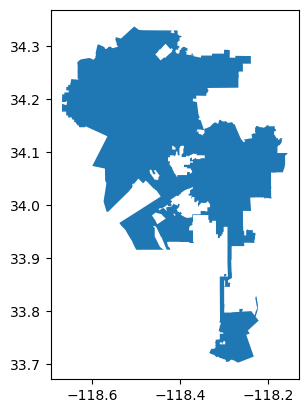

In [2]:
places = gpd.read_file('data/tl_2025_06_place.zip')
la = places[places['NAME'] == 'Los Angeles']

print(la.crs)
la.plot()

## Polygons: LA28 venues

We create a data frame with the venue coordinates and turn it into a geo-data frame, as in lesson 11.

In [3]:
venues = pd.DataFrame({
    'venue': ['LA Memorial Coliseum', 'SoFi Stadium', 'Intuit Dome',
              'Crypto.com Arena', 'Dodger Stadium', 'Rose Bowl'],
    'lon': [-118.2879, -118.3392, -118.3410, -118.2673, -118.2400, -118.1676],
    'lat': [34.0141, 33.9535, 33.9450, 34.0430, 34.0739, 34.1613],
})

venues = gpd.GeoDataFrame(venues,
                          geometry=gpd.points_from_xy(venues['lon'], venues['lat']),
                          crs='epsg:4326')
venues

,venue,lon,lat,geometry
0,LA Memorial Coliseum,-118.2879,34.0141,POINT (-118.28790 34.01410)
1,SoFi Stadium,-118.3392,33.9535,POINT (-118.33920 33.95350)
2,Intuit Dome,-118.3410,33.9450,POINT (-118.34100 33.94500)
3,Crypto.com Arena,-118.2673,34.0430,POINT (-118.26730 34.04300)
4,Dodger Stadium,-118.2400,34.0739,POINT (-118.24000 34.07390)
5,Rose Bowl,-118.1676,34.1613,POINT (-118.16760 34.16130)


🆕 **Not covered in class:** buffering. A venue is a point, but we want the temperature of the area around it. `.buffer(500)` draws a circle with a 500 m radius around each point.

The buffer distance is in the units of the CRS, so we must reproject to a projected CRS in meters first. Buffering in EPSG:4326 would give a radius of 500 *degrees*. We use UTM zone 11N (EPSG:32611), which is also the Landsat raster's CRS.

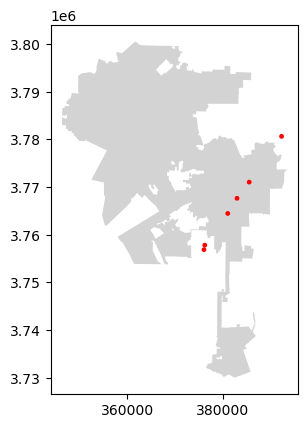

In [4]:
venues = venues.to_crs('epsg:32611')
venues['geometry'] = venues.buffer(500)

fig, ax = plt.subplots()
la.to_crs(venues.crs).plot(ax=ax, color='lightgray')
venues.plot(ax=ax, color='red')
plt.show()

The Rose Bowl (Pasadena) and SoFi Stadium and Intuit Dome (Inglewood) are outside the City of Los Angeles. We keep them: our comparison is "venue vs. city average", not "venues inside the city".

## STAC search: Landsat surface temperature

In [5]:
catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

# Bounding box of LA in lat/lon, as the search expects
la_bbox = list(la.to_crs('epsg:4326').total_bounds)

🆕 **Not covered in class:** filtering a search by item properties. Clouds hide the ground from the thermal sensor, so we only want nearly cloud-free scenes. The `query` parameter filters items by any property in their metadata, here `eo:cloud_cover` (a percentage).

In [6]:
search = catalog.search(
    collections=['landsat-c2-l2'],
    bbox=la_bbox,
    datetime='2026-06-01/2026-09-30',
    query={'eo:cloud_cover': {'lt': 10}},
)
items = search.item_collection()
len(items)

7

🆕 **Not covered in class:** choosing between overlapping scenes. Landsat scenes are tiles, and LA sits near the edge between two of them. A search can return tiles that only cover part of the city (it did for a single-date search while I was testing), so we check which footprints contain the whole city, using `shape()` from lesson 16.

In [7]:
la_4326 = la.to_crs('epsg:4326').geometry.iloc[0]

for item in items:
    footprint = shape(item.geometry)
    print(item.id,
          item.properties['eo:cloud_cover'],
          'covers LA:', footprint.contains(la_4326))

LC09_L2SP_041036_20260930_02_T1 0.64 covers LA: True
LC08_L2SP_041036_20260922_02_T1 0.43 covers LA: True
LC09_L2SP_041036_20260914_02_T1 1.62 covers LA: True
LC08_L2SP_041036_20260821_02_T1 0.21 covers LA: True
LC08_L2SP_041036_20260805_02_T1 8.48 covers LA: True
LC09_L2SP_041036_20260728_02_T1 6.44 covers LA: True
LC09_L2SP_041036_20260610_02_T1 1.89 covers LA: True


We pick the scene from **August 21, 2026** (Landsat 8): it covers all of LA and has the lowest cloud cover.

> **Student decision:** which date to use. Any clear summer scene works. Students should say why they picked theirs (cloud cover, heat wave, time of year).

In [8]:
item = [i for i in items if i.id == 'LC08_L2SP_041036_20260821_02_T1'][0]

print(item.properties['datetime'])

2026-08-21T18:28:05.822606Z


The time is in UTC: 18:28 UTC is **11:28 am** in Los Angeles. Landsat always passes over in the late morning, before the hottest part of the day. ECOSTRESS's map averaged 1 to 4 pm.

## Surface temperature raster

In [9]:
for key in item.assets.keys():
    print(key, '--', item.assets[key].title)

qa -- Surface Temperature Quality Assessment Band
ang -- Angle Coefficients File
red -- Red Band
blue -- Blue Band
drad -- Downwelled Radiance Band
emis -- Emissivity Band
emsd -- Emissivity Standard Deviation Band
trad -- Thermal Radiance Band
urad -- Upwelled Radiance Band
atran -- Atmospheric Transmittance Band
cdist -- Cloud Distance Band
green -- Green Band
nir08 -- Near Infrared Band 0.8
lwir11 -- Surface Temperature Band
swir16 -- Short-wave Infrared Band 1.6
swir22 -- Short-wave Infrared Band 2.2
coastal -- Coastal/Aerosol Band
mtl.txt -- Product Metadata File (txt)
mtl.xml -- Product Metadata File (xml)
mtl.json -- Product Metadata File (json)
qa_pixel -- Pixel Quality Assessment Band
qa_radsat -- Radiometric Saturation and Terrain Occlusion Quality Assessment Band
qa_aerosol -- Aerosol Quality Assessment Band
tilejson -- TileJSON with default rendering
rendered_preview -- Rendered preview


In [10]:
lst = rioxr.open_rasterio(item.assets['lwir11'].href)
lst = lst.squeeze('band', drop=True)

print('CRS:', lst.rio.crs)
print('Resolution:', lst.rio.resolution())
print('No-data value:', lst.rio.nodata)
print('Data type:', lst.dtype)
print('Attributes:', lst.attrs)

CRS: EPSG:32611
Resolution: (30.0, -30.0)
No-data value: 0
Data type: uint16
Attributes: {'AREA_OR_POINT': 'Point', '_FillValue': 0, 'scale_factor': 1.0, 'add_offset': 0.0}


🆕 **Not covered in class:** scale and offset. The values are `uint16` integers, not temperatures. To save space, Landsat stores each temperature as an integer, and we have to convert it back with:

$$\text{temperature (K)} = \text{value} \times \text{scale} + \text{offset}$$

Notice the file's own attributes say `scale_factor: 1.0` and `add_offset: 0.0`. That is **not** right for this product. The real values are in the STAC metadata for the asset:

In [11]:
item.assets['lwir11'].extra_fields['raster:bands']

[{'unit': 'kelvin',
  'scale': 0.00341802,
  'nodata': 0,
  'offset': 149,
  'data_type': 'uint16',
  'spatial_resolution': 30}]

## Clip to Los Angeles

As in lesson 17: match the CRS, clip to the bounding box first, then to the polygon.

In [12]:
la = la.to_crs(lst.rio.crs)
assert la.crs == lst.rio.crs

lst_la = lst.rio.clip_box(*la.total_bounds).rio.clip(la.geometry)

Now convert to °C. The no-data value is 0, and `rio.clip()` filled everything outside LA with 0. **We must turn the 0s into NaN before converting**, or they become -124 °C and drag every average down.

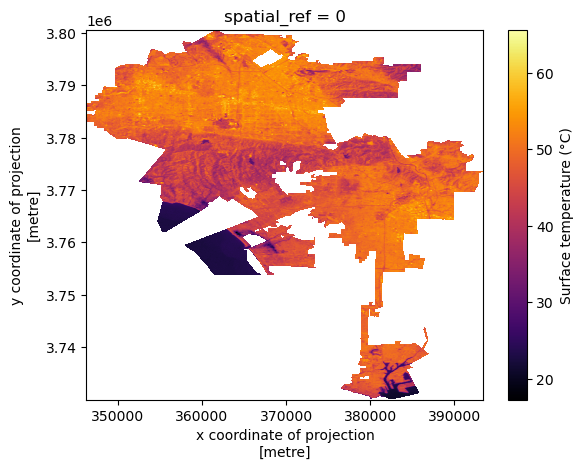

In [13]:
band = item.assets['lwir11'].extra_fields['raster:bands'][0]

lst_la = lst_la.where(lst_la != band['nodata'])            # 0 -> NaN
lst_la = lst_la * band['scale'] + band['offset'] - 273.15   # integers -> K -> °C

lst_la.plot(cmap='inferno', cbar_kwargs={'label': 'Surface temperature (°C)'})

Quick check that the values make sense:

In [14]:
print(f"Min: {float(lst_la.min()):.1f} °C")
print(f"Max: {float(lst_la.max()):.1f} °C")
print(f"Mean: {float(lst_la.mean()):.1f} °C")

Min: 17.3 °C
Max: 65.6 °C
Mean: 46.6 °C


> **Data check for students:** what are the coldest pixels (below 25 °C)? On the plot they are the ocean: **the TIGER boundary of Los Angeles includes water** (Santa Monica Bay off Venice, and the harbor). Those pixels pull the city average down. Students could notice this and decide what to do, e.g. use the Census *cartographic boundary* file, which follows the shoreline, or mask out water. I left the water in for this scratch version.
>
> The hottest pixels are rooftops and parking lots. Surface temperatures of 50+ °C are normal for asphalt on a summer day. **This is the temperature of the ground, not of the air.** Air temperature over hot pavement is usually much lower.

## Statistics: venues vs. the city average

The city average is our reference.

> **Student decision:** the threshold. "Hotter than the city average" is a simple choice; a fixed temperature (e.g. 50 °C) or a percentile are others. Students should justify theirs.

In [15]:
city_mean = float(lst_la.mean())
city_mean

46.58549880981445

🆕 **Not covered in class:** statistics per polygon. We clip the raster to each venue's buffer, one at a time. We start from a box around all the venues so each clip is fast.

In [16]:
# Small raster covering all venues, converted to °C
lst_venues = lst.rio.clip_box(*venues.total_bounds)
lst_venues = lst_venues.where(lst_venues != band['nodata'])
lst_venues = lst_venues * band['scale'] + band['offset'] - 273.15

mean_temps = []
pct_hot = []

for geom in venues.geometry:
    venue_lst = lst_venues.rio.clip([geom])
    n_pixels = int(venue_lst.notnull().sum())
    n_hot = int((venue_lst > city_mean).sum())

    mean_temps.append(float(venue_lst.mean()))
    pct_hot.append(n_hot / n_pixels * 100)

venues['mean_temp_c'] = mean_temps
venues['pct_above_city_mean'] = pct_hot

venues[['venue', 'mean_temp_c', 'pct_above_city_mean']].round(1).sort_values('mean_temp_c', ascending=False)

,venue,mean_temp_c,pct_above_city_mean
4,Dodger Stadium,50.2,87.5
3,Crypto.com Arena,49.1,86.3
2,Intuit Dome,47.3,65.9
5,Rose Bowl,47.3,51.1
0,LA Memorial Coliseum,47.0,44.2
1,SoFi Stadium,46.0,57.6


Each 500 m buffer covers about 870 Landsat pixels, but the thermal sensor's real resolution is 100 m, so each buffer holds only about 80 independent measurements.

## Map

Surface temperature over LA with the venue buffers and a basemap (contextily, as in discussion section 8).

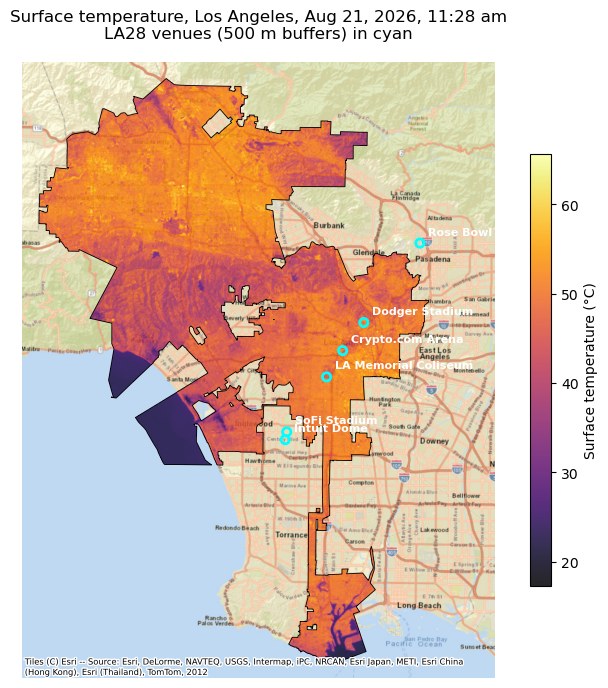

In [17]:
fig, ax = plt.subplots(figsize=(9, 8))

lst_la.plot(ax=ax, cmap='inferno', alpha=0.85,
            cbar_kwargs={'label': 'Surface temperature (°C)', 'shrink': 0.7})
la.boundary.plot(ax=ax, color='black', linewidth=0.6)
venues.boundary.plot(ax=ax, color='cyan', linewidth=2)

for x, y, name in zip(venues.centroid.x, venues.centroid.y, venues['venue']):
    ax.annotate(name, (x, y), xytext=(6, 6), textcoords='offset points',
                color='white', fontsize=8, fontweight='bold')

# Zoom out enough to show the venues outside the city
xmin, ymin, xmax, ymax = la.total_bounds
ax.set_xlim(xmin - 2000, xmax + 8000)
ax.set_ylim(ymin - 2000, ymax + 2000)

ctx.add_basemap(ax, crs=la.crs, source=ctx.providers.Esri.WorldStreetMap, attribution_size=6)

ax.set_title('Surface temperature, Los Angeles, Aug 21, 2026, 11:28 am\n'
             'LA28 venues (500 m buffers) in cyan')
ax.set_axis_off()
plt.show()

## Possible reflection questions for students

1. Landsat measured at 11:28 am. Would you expect the ranking of venues to change in the late afternoon? Why might ECOSTRESS be better for this question?
2. Is surface temperature a good measure of heat risk for spectators? What would you need to know besides it?
3. The thermal band is 100 m resampled to 30 m. Is a single stadium resolved in this data?
4. How would your results change on a different date? Try one more scene.